# Simheuristic for the Team Orienteering Problem with stochastic travel times

**Stochastic Team Orienteering Problem (TOP).** A source node $0$, a sink node $n+1$ and $n$ customers. Customer $i$ pays a reward $u_i \ge 0$ the first time it is visited. $m$ identical vehicles leave the source, end at the sink and visit customers in between. The *expected* travel time $t_{ij}$ is the Euclidean distance, and each route must satisfy the design constraint

$$\sum_{(i,j)\in \text{route}} t_{ij} \le t_{max}.$$

The real travel times are random: $T_{ij} = T_{ji} \sim \text{LogNormal}(\mu_{ij}, \sigma_{ij})$ with $E[T_{ij}] = t_{ij}$ and $\text{Var}[T_{ij}] = c\,t_{ij}$, where $c \in \{0.05, 0.25, 0.75\}$ is the uncertainty level (L, M, H). A route whose *real* time exceeds $t_{max}$ **loses the whole reward of the route**. The goal is to maximise the expected collected reward

$$\max \; E\Big[\sum_j U_j\Big], \qquad U_j = \begin{cases} u_j & j \text{ is on a route that ends within } t_{max},\\ 0 & \text{otherwise.}\end{cases}$$

The lognormal parameters follow from the two moments:

$$\sigma_{ij}^2 = \ln\!\Big(1 + \frac{c}{t_{ij}}\Big), \qquad \mu_{ij} = \ln t_{ij} - \tfrac12 \sigma_{ij}^2 .$$

**The method: a simheuristic.** A fast heuristic for the *deterministic* TOP proposes many good solutions, and Monte Carlo simulation then judges the most promising ones under the random times. For one case (instance, $c$, $\alpha$, seed):

```
1. arcs  <- arcs (i, j) between reachable customers, sorted by the enriched savings
            alpha * s_ij + (1 - alpha) * (u_i + u_j),   s_ij = t_i,sink + t_0,j - t_ij
2. cands <- local_search(PJS greedy)  +  50 x local_search(PJS with biased randomisation, beta = 0.3)
3. distinct <- cands without duplicated solutions (same set of routes)
4. top7  <- the 7 distinct solutions with the highest deterministic reward
5. draw 200 scenarios T_fast, the SAME for the 7 (common random numbers); simulate them
   top3  <- the 3 with the highest simulated mean reward
6. draw 1000 NEW scenarios T_int; simulate the 3
7. return the solution with the highest mean reward in step 6
```

PJS is the parallel savings heuristic of the TOP: one route per customer, merged along the sorted arcs while the expected time stays within $t_{max}$. Biased randomisation (BR) picks, at each step, the arc at position $k = \lfloor \ln U / \ln(1-\beta) \rfloor \bmod L$ of the list (geometric, $U$ uniform), so good arcs are favoured but not always chosen. The local search repeats 2-opt on every route and the insertion of the best-reward customer that fits.

| Parameter | Value |
|---|---|
| Uncertainty level $c$ (L / M / H) | 0.05 / 0.25 / 0.75 |
| Savings weight $\alpha$ | 0.25, 0.5, 0.75 (all three are run) |
| BR parameter $\beta$ and BR constructions | 0.3 and 50 (plus one greedy) |
| Candidates to the fast / intensive simulation | 7 / 3 |
| Replicas of the fast / intensive simulation | 200 / 1000 |
| Base seed | 2019 (one `SeedSequence` per case, see section 9) |

**Scope.** The notebook covers the small instances of Chao et al. (sets p1, p2 and p3: 141 instances with a known BKS, at most 33 nodes); the SAA model solved with CPLEX in the paper is not implemented. The search runs a fixed number of iterations (50 BR constructions; the paper does not specify its stopping criterion), and the simulation only judges the 7 best deterministic candidates instead of being called inside the search loop, so the figures are comparable with the paper's in ordering and magnitude, not point by point.

**What this notebook does.** All the algorithm lives in [simtop.py](simtop.py). Sections 1-8 call its functions one by one on a small instance (`p2.3.g`); section 9 runs the whole simheuristic on it, and sections 10-17 analyse the 1 269 runs of the full experiment, generated by [run_experiment.py](run_experiment.py).

> Juan, A. A., Reyes-Rubiano, L., de la Torre, R., Panadero, J., Faulin, J. and Latorre, I. (2019). *Simulation-based optimization in transportation and logistics: comparing sample average approximation with simheuristics.* Proceedings of the 2019 Winter Simulation Conference, pp. 1906-1917. Instances: Chao, Golden and Wasil (1996). Best-known solutions (BKS): Dang et al. (2013).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import simtop as st

RES = Path("../results")
FIG = RES / "figures"
FIG.mkdir(parents=True, exist_ok=True)
LEVEL = {0.05: "L", 0.25: "M", 0.75: "H"}
levels = ["L", "M", "H"]
ROUTE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, MUTED = "#0b0b0b", "#8a8984"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "font.size": 9})

In [2]:
def plot_routes(inst, sol, ax, title=""):
    """Draw source (square), sink (diamond), customers (size ~ reward, hollow if unreachable) and the routes."""
    reach = st.reachable(inst)
    ids = np.arange(1, inst.n - 1)
    ax.scatter(inst.x[ids], inst.y[ids], s=15 + 3 * inst.reward[ids], c=np.where(reach[ids], INK, "white"),
               edgecolors=INK, linewidths=0.8, zorder=2)
    ax.scatter(inst.x[0], inst.y[0], s=80, marker="s", c=INK, zorder=3)
    ax.scatter(inst.x[-1], inst.y[-1], s=80, marker="D", c=MUTED, zorder=3)
    for k, route in enumerate(sol):
        path = [0, *route, inst.n - 1]
        ax.plot(inst.x[path], inst.y[path], color=ROUTE_COLORS[k % len(ROUTE_COLORS)], lw=1.8, zorder=1,
                label=f"route {k + 1}")
    ax.set_title(title, loc="left", color=INK)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


def describe(inst, sol):
    """Table with one row per route: customers, reward, expected time and share of tmax."""
    rows = [{"route": " ".join(map(str, r)), "reward": inst.reward[list(r)].sum(),
             "time": st.route_time(inst, r), "time/tmax": st.route_time(inst, r) / inst.tmax} for r in sol]
    return pd.DataFrame(rows).round(2)

In [3]:
def plot_gap_by_c_alpha(runs):
    """Boxplots of the gap, one panel per c, one box per alpha; saved as gap_by_c_alpha.png."""
    alphas = sorted(runs.alpha.unique())
    fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
    for ax, c in zip(axes, sorted(runs.c.unique())):
        ax.boxplot([runs[(runs.c == c) & (runs.alpha == a)].gap_pct for a in alphas],
                   tick_labels=[str(a) for a in alphas])
        ax.set_title(f"c = {c} ({LEVEL[c]})")
        ax.set_xlabel("alpha")
    axes[0].set_ylabel("gap to BKS (%)")
    fig.tight_layout()
    fig.savefig(FIG / "gap_by_c_alpha.png", dpi=150)
    plt.show()


def plot_best_vs_paper(best, paper):
    """Boxplots of our gap (best alpha) next to the boxes of Fig. 3; saved as gap_best_vs_paper.png."""
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.boxplot([best[best.level == l].gap_pct for l in levels], positions=[1, 4, 7], widths=0.8,
               patch_artist=True, boxprops=dict(facecolor="tab:blue", alpha=0.6))
    stats = [dict(paper[l], fliers=[26] if l == "L" else [], label=l) for l in levels]
    ax.bxp(stats, positions=[2, 5, 8], widths=0.8, patch_artist=True,
           boxprops=dict(facecolor="tab:orange", alpha=0.6))
    ax.set_xticks([1.5, 4.5, 7.5])
    ax.set_xticklabels(["L (c=0.05)", "M (c=0.25)", "H (c=0.75)"])
    ax.set_ylabel("gap to BKS (%)")
    ax.set_title("Best alpha per instance (blue, ours) vs SimHeu Fig. 3 (orange, read by eye)")
    fig.tight_layout()
    fig.savefig(FIG / "gap_best_vs_paper.png", dpi=150)
    plt.show()


def plot_gap_by_set_tmax(best):
    """Left: gap by set and level (boxes); right: gap against tmax. Saved as gap_by_set_tmax.png."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    sets = sorted(best.set.unique())
    colors = ["tab:green", "tab:orange", "tab:red"]
    handles = []
    for k, (l, col) in enumerate(zip(levels, colors)):
        bp = axes[0].boxplot([best[(best.level == l) & (best.set == s)].gap_pct for s in sets],
                             positions=np.arange(len(sets)) * 4 + k, widths=0.8, patch_artist=True)
        for box in bp["boxes"]:
            box.set(facecolor=col, alpha=0.5)
        handles.append(bp["boxes"][0])
    axes[0].set_xticks(np.arange(len(sets)) * 4 + 1)
    axes[0].set_xticklabels(sets)
    axes[0].set_title("gap by set (within each set: L, M, H)")
    axes[0].set_ylabel("gap to BKS (%)")
    axes[0].legend(handles, levels, title="level")
    for l, col in zip(levels, colors):
        d = best[best.level == l]
        axes[1].scatter(d.tmax, d.gap_pct, s=12, alpha=0.6, c=col, label=l)
    axes[1].set_xscale("log")
    axes[1].set_xlabel("tmax")
    axes[1].set_ylabel("gap to BKS (%)")
    axes[1].legend()
    axes[1].set_title("gap against tmax (best alpha)")
    fig.tight_layout()
    fig.savefig(FIG / "gap_by_set_tmax.png", dpi=150)
    plt.show()


def plot_decomposition(det_m, unc_m):
    """Stacked bars: deterministic gap + loss due to uncertainty; saved as gap_decomposition.png."""
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(levels, det_m, label="deterministic gap")
    ax.bar(levels, unc_m, bottom=det_m, label="loss due to uncertainty (relative to BKS)")
    ax.set_ylabel("% of the BKS (means)")
    ax.legend()
    ax.set_title("Decomposition of the gap (best alpha)")
    fig.tight_layout()
    fig.savefig(FIG / "gap_decomposition.png", dpi=150)
    plt.show()


def plot_fail_rate(best):
    """Boxplot of the percentage of failed routes by level; saved as fail_rate_by_level.png."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.boxplot([best[best.level == l].fail_rate for l in levels], tick_labels=levels)
    ax.set_ylabel("failed routes (%)")
    ax.set_xlabel("level")
    ax.set_title("Failed routes, best alpha per instance")
    fig.tight_layout()
    fig.savefig(FIG / "fail_rate_by_level.png", dpi=150)
    plt.show()

## 1. Loading an instance

`st.load_instance(name)` reads `../data/top-data/<name>.txt` (header `n;`, `m;`, `tmax;`, then one line `x;y;reward` per node) and returns an `Instance` with the coordinates, the rewards and the expected-time matrix `t`. Node 0 is the source and node $n-1$ the sink (the file's $n$ counts both).

The running example is **p2.3.g**: 21 nodes, 3 vehicles. A customer is *reachable* if it fits alone in a route ($t_{0i} + t_{i,sink} \le t_{max}$); `st.reachable(inst)` flags them, and the unreachable ones are ignored by the whole method.

In [4]:
name = "p2.3.g"
inst = st.load_instance(name)
reach = st.reachable(inst)
print(f"{inst.name}: n = {inst.n} nodes (source 0, sink {inst.n - 1}), m = {inst.m} vehicles, tmax = {inst.tmax}")
print(f"total reward = {inst.reward.sum():g}; reachable customers: {reach.sum()} of {inst.n - 2}")
pd.DataFrame({"x": inst.x, "y": inst.y, "reward": inst.reward, "reachable": reach}).head(6)

p2.3.g: n = 21 nodes (source 0, sink 20), m = 3 vehicles, tmax = 10.7
total reward = 450; reachable customers: 10 of 19


,x,y,reward,reachable
0,4.6,7.1,0.0,False
1,5.7,11.4,20.0,True
2,4.4,12.3,20.0,False
3,2.8,14.3,30.0,False
4,3.2,10.3,15.0,True
5,3.5,9.8,15.0,True


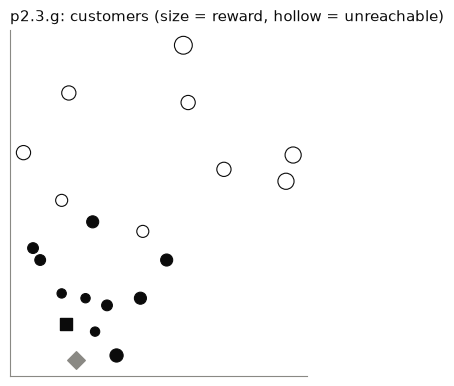

In [5]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
plot_routes(inst, [], ax, f"{name}: customers (size = reward, hollow = unreachable)")
plt.show()

## 2. Expected travel times

`st.travel_times(x, y)` (called by `load_instance`) gives the $n \times n$ matrix of Euclidean distances $t_{ij}$, not rounded. It is symmetric with a zero diagonal. These expected times drive the construction and the local search; the random times only appear in the simulation.

In [6]:
t = inst.t
print("shape:", t.shape, "| symmetric:", np.allclose(t, t.T), "| zero diagonal:", bool(np.all(np.diag(t) == 0)))
print("t(source, i) + t(i, sink) for customers 1..6:", (t[0, 1:7] + t[1:7, -1]).round(2), "| tmax =", inst.tmax)

shape: (21, 21) | symmetric: True | zero diagonal: True
t(source, i) + t(i, sink) for customers 1..6: [10.28 11.93 16.4   8.53  7.38  4.18] | tmax = 10.7


## 3. The lognormal law

`st.lognormal_params(t, c)` returns the matrices $\mu_{ij}, \sigma_{ij}$ such that $E[T_{ij}] = t_{ij}$ and $\text{Var}[T_{ij}] = c\,t_{ij}$ (and $0$ where $t_{ij} = 0$, to avoid $\ln 0$). Because the variance is proportional to $t$ and not to $t^2$, the relative variability $\sqrt{c\,t}/t$ is larger on short arcs. The table checks the formulas for $t = 10$ with $10^6$ samples per level.

In [7]:
t10 = np.array([[0.0, 10.0], [10.0, 0.0]])
rng = np.random.default_rng(1)
rows = []
for c in st.C_LEVELS:
    mu, sg = st.lognormal_params(t10, c)
    x = rng.lognormal(mu[0, 1], sg[0, 1], 10**6)
    rows.append({"c": c, "mu": mu[0, 1], "sigma": sg[0, 1], "CV % (theory)": 100 * np.sqrt(c * 10) / 10,
                 "sample mean": x.mean(), "var (theory)": c * 10, "sample var": x.var()})
pd.DataFrame(rows).round(4)

,c,mu,sigma,CV % (theory),sample mean,var (theory),sample var
0,0.05,2.3001,0.0706,7.0711,9.9998,0.5,0.4984
1,0.25,2.2902,0.1571,15.8114,10.0026,2.5,2.4988
2,0.75,2.2664,0.2689,27.3861,10.0039,7.5,7.5115


## 4. Savings arcs

`st.savings_arcs(inst, alpha)` builds, for every ordered pair $(i, j)$ of reachable customers, the arc $i \to j$ with the saving $s_{ij} = t_{i,sink} + t_{0j} - t_{ij}$ (time saved by serving $j$ right after $i$ instead of in two separate routes) and sorts the arcs by the enriched value

$$\alpha\, s_{ij} + (1-\alpha)(u_i + u_j).$$

Distance and reward have different scales, so the three values of $\alpha$ are all tried. Ties keep the generation order (stable sort). The function returns two arrays, `arc_i` and `arc_j`.

In [8]:
alpha, c = 0.5, 0.25
arc_i, arc_j = st.savings_arcs(inst, alpha, reach)
sink = inst.n - 1
s_ij = inst.t[arc_i, sink] + inst.t[0, arc_j] - inst.t[arc_i, arc_j]
enriched = alpha * s_ij + (1 - alpha) * (inst.reward[arc_i] + inst.reward[arc_j])
k = int(reach.sum())
print(f"{k} reachable customers -> {len(arc_i)} directed arcs (= k(k-1) = {k * (k - 1)}); sorted: {bool(np.all(np.diff(enriched) <= 1e-12))}")
pd.DataFrame({"i": arc_i, "j": arc_j, "s_ij": s_ij, "u_i+u_j": inst.reward[arc_i] + inst.reward[arc_j],
              "enriched": enriched}).head(6).round(2)

10 reachable customers -> 90 directed arcs (= k(k-1) = 90); sorted: True


,i,j,s_ij,u_i+u_j,enriched
0,9,13,3.62,45.0,24.31
1,8,13,3.62,45.0,24.31
2,1,13,2.62,45.0,23.81
3,13,9,2.40,45.0,23.70
4,1,8,7.35,40.0,23.67
5,13,8,2.19,45.0,23.59


## 5. PJS construction: greedy and biased randomised

`st.pjs_construct(inst, alpha, selector, rng, beta)` starts with one route per reachable customer and walks the arc list: the arc $(i, j)$ merges two routes if $i$ ends one, $j$ starts the other, and the merged route still takes at most $t_{max}$ (checked leg by leg). At the end it keeps the $m$ best routes, ordered by reward and then by time. It returns the solution as a list of routes.

* `selector="greedy"` walks the list in order.
* `selector="br"` picks, at each step, the arc at position $k = \lfloor \ln U / \ln(1-\beta) \rfloor \bmod L$ of the remaining list, so position $k$ has probability about $\beta(1-\beta)^k$. It needs a generator `rng`.

In [9]:
greedy = st.pjs_construct(inst, alpha, arcs=(arc_i, arc_j), reach=reach)
print("greedy PJS, total reward", st.det_reward(inst, greedy))
describe(inst, greedy)

greedy PJS, total reward 130.0


,route,reward,time,time/tmax
0,9 13 10,60.0,10.67,1.00
1,6 1 11,40.0,10.43,0.97
2,5 4,30.0,8.53,0.80


In [10]:
print("P(position k), beta = 0.3:", [round(st.BETA * (1 - st.BETA) ** k, 3) for k in range(5)])
rng_demo = np.random.default_rng(7)
br_sols = [st.pjs_construct(inst, alpha, "br", rng_demo, arcs=(arc_i, arc_j), reach=reach) for _ in range(6)]
print("rewards of 6 BR constructions:", [st.det_reward(inst, s) for s in br_sols],
      "| distinct from the greedy one:", sum(st.canonical(s) != st.canonical(greedy) for s in br_sols))

P(position k), beta = 0.3: [0.3, 0.21, 0.147, 0.103, 0.072]
rewards of 6 BR constructions: [130.0, 140.0, 125.0, 130.0, 140.0, 130.0] | distinct from the greedy one: 5


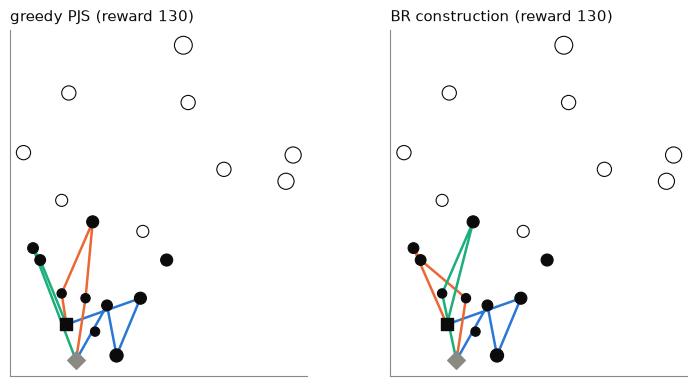

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
plot_routes(inst, greedy, axes[0], f"greedy PJS (reward {st.det_reward(inst, greedy):g})")
plot_routes(inst, br_sols[0], axes[1], f"BR construction (reward {st.det_reward(inst, br_sols[0]):g})")
plt.show()

## 6. Local search

`st.local_search(inst, sol)` repeats until nothing can be inserted: 2-opt (first improvement) in every route, then the insertion of the unvisited reachable customer with the highest reward at its cheapest feasible position. It never lowers the reward and never exceeds $t_{max}$. Shorter routes after 2-opt leave room for more customers.

In [12]:
improved = st.local_search(inst, greedy, reach)
print(f"greedy: reward {st.det_reward(inst, greedy):g}, total time {st.det_time(inst, greedy):.2f}"
      f"  ->  after local search: reward {st.det_reward(inst, improved):g}, total time {st.det_time(inst, improved):.2f}")
print("BR constructions, reward before -> after:",
      [(st.det_reward(inst, s), st.det_reward(inst, st.local_search(inst, s, reach))) for s in br_sols])
describe(inst, improved)

greedy: reward 130, total time 29.63  ->  after local search: reward 140, total time 26.85
BR constructions, reward before -> after: [(130.0, 140.0), (140.0, 140.0), (125.0, 145.0), (130.0, 140.0), (140.0, 140.0), (130.0, 140.0)]


,route,reward,time,time/tmax
0,10 9 13,60.0,7.62,0.71
1,6 1 11 12,50.0,10.70,1.00
2,5 4,30.0,8.53,0.80


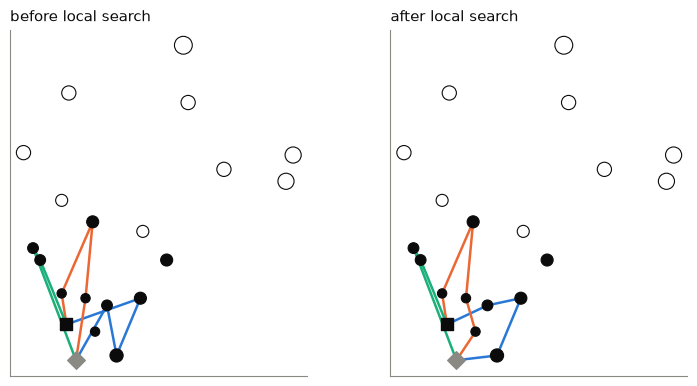

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
plot_routes(inst, greedy, axes[0], "before local search")
plot_routes(inst, improved, axes[1], "after local search")
plt.show()

## 7. Candidates, duplicates and the deterministic filter

A run needs its three random generators. `st.case_seed(idx_inst, idx_c, idx_alpha)` is the `SeedSequence([2019, idx_inst, idx_c, idx_alpha])` of the case, where `idx_inst` is the position of the instance in the alphabetical list of **all 387** Chao files (`st.instance_names()`), so the seed does not depend on which instances are run. `st.spawn_rngs(seed)` splits it into three independent generators: biased randomisation, fast simulation and intensive simulation.

`st.generate_candidates(inst, alpha, rng_br)` builds the greedy solution plus 50 BR solutions, each improved by local search, and returns all 51 and the *distinct* ones (the same set of routes, in any order, counts once). `st.deterministic_filter(inst, distinct)` keeps the 7 with the highest deterministic reward (ties: shorter total time, then generation order).

In [14]:
idx_inst = st.instance_names().index(name)
seed = st.case_seed(idx_inst, 1, 1)                  # c index 1 = 0.25, alpha index 1 = 0.5
rng_br, rng_fast, rng_int = st.spawn_rngs(seed)
cands, distinct = st.generate_candidates(inst, alpha, rng_br)
print(f"idx_inst = {idx_inst}; seed entropy = {seed.entropy}")
print(f"{len(cands)} candidates -> {len(distinct)} distinct; rewards of the distinct ones:",
      sorted((st.det_reward(inst, s) for _, s in distinct), reverse=True))
top = st.deterministic_filter(inst, distinct)
pd.DataFrame([{"rank": q + 1, "k (generation order)": r[2], "reward": -r[0], "total time": r[1]}
              for q, r in enumerate(top)]).round(2)

idx_inst = 71; seed entropy = [2019, 71, 1, 1]
51 candidates -> 10 distinct; rewards of the distinct ones: [145.0, 140.0, 140.0, 140.0, 140.0, 140.0, 140.0, 140.0, 140.0, 130.0]


,rank,k (generation order),reward,total time
0,1,20,145.0,31.51
1,2,0,140.0,26.85
2,3,30,140.0,27.21
3,4,6,140.0,27.42
4,5,36,140.0,27.58
5,6,1,140.0,27.66
6,7,17,140.0,28.30


## 8. Scenarios and simulation

`st.sample_scenarios(mu, sigma, t, R, rng)` draws $R$ replicas of the whole matrix of travel times, $T[r, i, j] = T[r, j, i]$, as $\exp(\mu + \sigma Z)$ with $Z \sim N(0,1)$ (zero where $t_{ij} = 0$). `st.simulate(inst, sol, T)` returns, for a solution and a set of replicas, the mean and standard deviation of the collected reward (a route that overruns $t_{max}$ pays nothing) and the percentage of routes that overrun.

The fast simulation gives **the same replicas $T$ to all candidates** (common random numbers). Then the difference between two candidates comes from their routes and not from luck with the draws. The second cell shows it for the two best candidates: the standard deviation of the difference of their mean rewards over 100 repetitions of the 200-replica simulation, with common and with independent replicas.

In [15]:
mu, sigma = st.lognormal_params(inst.t, c)
T_fast = st.sample_scenarios(mu, sigma, inst.t, st.R_FAST, rng_fast)
sym = np.array_equal(T_fast, T_fast.transpose(0, 2, 1)) and bool(np.all(np.diagonal(T_fast, axis1=1, axis2=2) == 0))
print(f"T_fast shape {T_fast.shape}; symmetric with zero diagonal: {sym}; "
      f"max |mean T - t| = {np.abs(T_fast.mean(0) - inst.t).max():.3f}")
sims = [st.simulate(inst, r[3], T_fast) for r in top]
pd.DataFrame([{"rank": q + 1, "det reward": -r[0], "fast mean": s[0], "std": s[1], "routes failing %": s[2]}
              for q, (r, s) in enumerate(zip(top, sims))]).round(1)

T_fast shape (200, 21, 21); symmetric with zero diagonal: True; max |mean T - t| = 0.254


,rank,det reward,fast mean,std,routes failing %
0,1,145.0,90.7,40.0,37.8
1,2,140.0,112.6,26.8,18.7
2,3,140.0,119.6,24.6,16.5
3,4,140.0,116.0,26.4,19.5
4,5,140.0,123.3,28.7,14.2
5,6,140.0,119.2,27.4,15.7
6,7,140.0,116.8,27.8,20.7


In [16]:
A, B = top[0][3], top[1][3]
rng_c = np.random.default_rng(11)
diff = {"common": [], "independent": []}
for _ in range(100):
    Ta = st.sample_scenarios(mu, sigma, inst.t, st.R_FAST, rng_c)
    Tb = st.sample_scenarios(mu, sigma, inst.t, st.R_FAST, rng_c)
    diff["common"].append(st.simulate(inst, A, Ta)[0] - st.simulate(inst, B, Ta)[0])
    diff["independent"].append(st.simulate(inst, A, Ta)[0] - st.simulate(inst, B, Tb)[0])
print({k: f"sd of the difference = {np.std(v, ddof=1):.2f}" for k, v in diff.items()})

{'common': 'sd of the difference = 3.23', 'independent': 'sd of the difference = 3.84'}


With common replicas the comparison between the two candidates is less noisy (standard deviation 3.23 against 3.84 with independent replicas in the printout above).

## 9. One complete run

`st.fast_screen(inst, top, T_fast)` simulates the 7 with the common $T_{fast}$ and keeps the 3 with the highest mean; `st.intensive_winner(inst, top, order, T_int)` simulates those 3 on 1000 **new** replicas $T_{int}$ (drawn from an independent generator) and picks the best. `st.simheuristic(inst, c, alpha, seed)` chains all the steps of sections 7-9; the cell checks that it reproduces the step-by-step result and the row of `../results/runs.csv` for this case.

In [17]:
order, fast = st.fast_screen(inst, top, T_fast)
T_int = st.sample_scenarios(mu, sigma, inst.t, st.R_INT, rng_int)
w, final = st.intensive_winner(inst, top, order, T_int)
pd.DataFrame([{"finalist": q + 1, "rank by det. reward": order[q] + 1, "det reward": -top[order[q]][0],
               "fast mean": fast[order[q]], "intensive mean": final[q][0], "std": final[q][1],
               "routes failing %": final[q][2]} for q in range(len(order))]).round(1)

,finalist,rank by det. reward,det reward,fast mean,intensive mean,std,routes failing %
0,1,5,140.0,123.3,119.2,26.8,18.4
1,2,3,140.0,119.6,118.2,24.3,18.2
2,3,6,140.0,119.2,115.6,29.0,18.8


In [18]:
res = st.simheuristic(inst, c, alpha, seed)
row = pd.read_csv(RES / "runs.csv").query("instance == @name and c == @c and alpha == @alpha").iloc[0]
print("winner:", res["routes"], f"| det reward {res['det_reward']:g}, expected reward {res['exp_reward']:.2f}, "
      f"routes failing {res['fail_rate']:.1f} %")
print("same as the step-by-step cells:", res["exp_reward"] == final[w][0] and res["routes"] == top[order[w]][3])
print("same as runs.csv:", res["exp_reward"] == row.exp_reward and st.format_routes(res["routes"]) == row.routes)
print(f"best deterministic candidate: reward {res['max_det_reward']:g}; greedy + local search: {res['greedy_ls_reward']:g}")

winner: [(10, 9, 13, 12), (6, 5, 4), (1, 11)] | det reward 140, expected reward 119.17, routes failing 18.4 %
same as the step-by-step cells: True
same as runs.csv: True
best deterministic candidate: reward 145; greedy + local search: 140


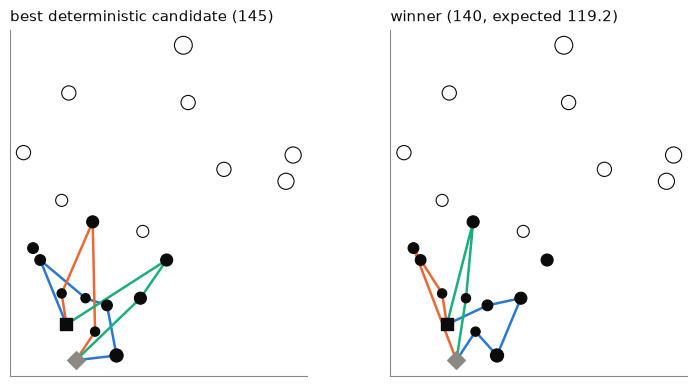

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
plot_routes(inst, top[0][3], axes[0], f"best deterministic candidate ({-top[0][0]:g})")
plot_routes(inst, res["routes"], axes[1], f"winner ({res['det_reward']:g}, expected {res['exp_reward']:.1f})")
plt.show()

The winner is not always the candidate with the highest deterministic reward: the simulation penalises routes that use almost all of $t_{max}$ because they overrun often and lose their whole reward.

## 10. The full experiment

**Design.** 141 instances of p1-p3 $\times$ 3 values of $c$ $\times$ 3 values of $\alpha$ = **1 269 runs**, one seed per case, `SeedSequence([2019, idx_inst, idx_c, idx_alpha])`, so the results do not depend on the execution order. The experiment takes about 25-40 s (more than 1 min if Numba has to compile), so this notebook reads its output instead of rerunning it. To regenerate `runs.csv` and `best.csv`:

```
uv run python src/run_experiment.py
```

`runs.csv` has one row per run; `best.csv` keeps, for every (instance, $c$), the $\alpha$ with the highest `exp_reward` (ties go to the smallest $\alpha$). The **gap** is $100\,(\text{BKS} - \text{exp\_reward})/\text{BKS}$, with BKS the best-known deterministic solution of the Chao instances and `exp_reward` the intensive-simulation mean of the winner. `fail_rate` is the percentage of routes that overrun $t_{max}$ in the intensive replicas.

In [20]:
runs = pd.read_csv(RES / "runs.csv")
best = pd.read_csv(RES / "best.csv")
runs["level"] = runs.c.map(LEVEL)
best["level"] = best.c.map(LEVEL)
print(len(runs), "runs,", len(best), "best rows,", runs.instance.nunique(), "instances")

1269 runs, 423 best rows, 141 instances


## 11. Does $\alpha$ matter?

The table gives the mean and median gap of each $(\alpha, c)$ cell over the 141 instances.

In [21]:
mean_t = runs.pivot_table(index="alpha", columns="c", values="gap_pct", aggfunc="mean")
med_t = runs.pivot_table(index="alpha", columns="c", values="gap_pct", aggfunc="median")
matrix = pd.concat({"mean_gap_pct": mean_t, "median_gap_pct": med_t}, axis=1).round(2)
matrix.to_csv(RES / "gap_alpha_c_matrix.csv")
matrix

mean_gap_pct               median_gap_pct              
c             0.05   0.25   0.75           0.05   0.25   0.75
alpha                                                        
0.25         16.69  26.92  31.78          16.90  27.52  33.02
0.50         16.86  26.83  31.97          16.94  28.56  32.42
0.75         16.29  26.90  31.94          17.07  28.77  33.45

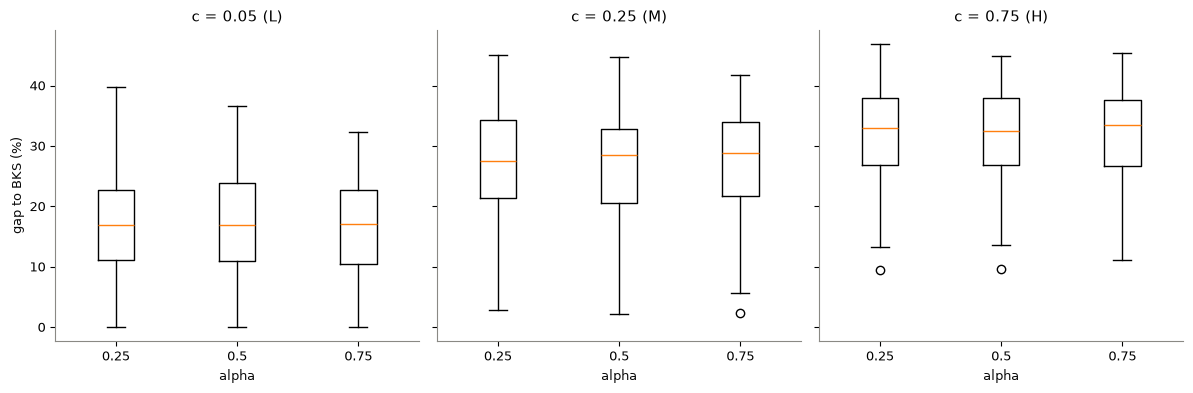

In [22]:
plot_gap_by_c_alpha(runs)

Within each panel the three boxes are almost the same: the choice of $\alpha$ moves the mean gap by less than 0.7 points, while changing $c$ moves it by about 10 points or more. The gap grows from the left panel to the right one.

## 12. Best $\alpha$ per (instance, $c$) against the paper's Fig. 3

For every instance and level we keep the best of the three $\alpha$ (`best.csv`) and compare the distribution of the gap with SimHeu-L/M/H of Fig. 3 (p. 1914) of Juan et al. (2019). The paper gives no table: its values are approximate, **read by eye** from the figure (about $\pm$1-2 points): median, Q1-Q3, whiskers and the one outlier of SimHeu-L (about 26). The paper does not say which instances the figure covers (we assume p1-p3, the ones the SAA could solve).

In [23]:
paper = {"L": dict(med=7, q1=5, q3=10, whislo=1, whishi=13), "M": dict(med=17, q1=9, q3=20, whislo=6, whishi=29),
         "H": dict(med=24, q1=19, q3=28, whislo=12, whishi=31)}
q = best.groupby("level").gap_pct.quantile([0.25, 0.5, 0.75]).unstack().loc[levels]
q.columns = ["q1", "median", "q3"]
q["mean"] = best.groupby("level").gap_pct.mean().loc[levels]
q["paper_q1"] = [paper[l]["q1"] for l in levels]
q["paper_median"] = [paper[l]["med"] for l in levels]
q["paper_q3"] = [paper[l]["q3"] for l in levels]
q = q.round(2)
q.to_csv(RES / "gap_best_by_level.csv")
q

,q1,median,q3,mean,paper_q1,paper_median,paper_q3
level,,,,,,,
L,9.90,15.69,20.23,14.65,5,7,10
M,20.04,26.02,31.97,25.02,9,17,20
H,26.35,31.56,36.44,30.51,19,24,28


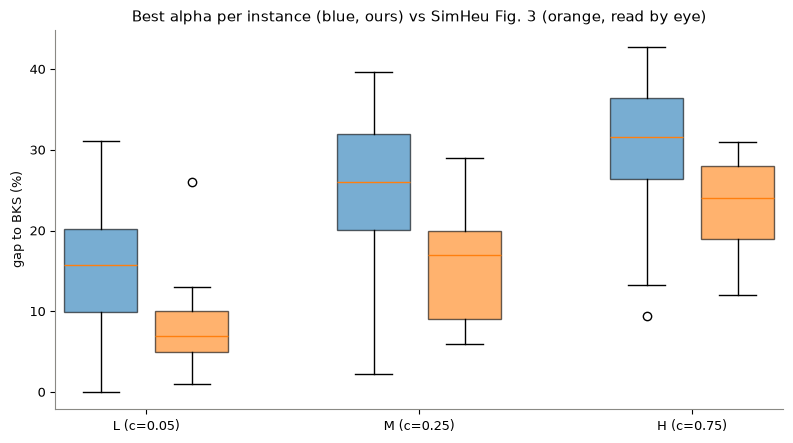

In [24]:
plot_best_vs_paper(best, paper)

Our boxes have the same order L < M < H as the paper's but sit higher: the medians are 7-9 points above SimHeu's at every level. The paper simulates inside its search (with runs of up to about 400 s in its Fig. 4), which can steer the search towards routes with slack; we only simulate 7 candidates chosen with expected times. We cannot check this without the authors' code.

In [25]:
mg = best.groupby("level").gap_pct.mean().loc[levels]
print("best alpha, mean gap:", mg.round(2).to_dict())
print("gap(L) < gap(M) < gap(H):", bool(mg["L"] < mg["M"] < mg["H"]))
mg_all = runs.groupby("level").gap_pct.mean().loc[levels]
print("all runs, mean gap:", mg_all.round(2).to_dict(), "monotone:", bool(mg_all["L"] < mg_all["M"] < mg_all["H"]))

best alpha, mean gap: {'L': 14.65, 'M': 25.02, 'H': 30.51}
gap(L) < gap(M) < gap(H): True
all runs, mean gap: {'L': 16.62, 'M': 26.88, 'H': 31.9} monotone: True


## 13. Gap by set and against $t_{max}$

With $\text{Var} = c\,t$ the relative uncertainty of a route is $\sqrt{c / E_r}$, larger for short routes, so one might expect larger gaps when $t_{max}$ is small. Does the data show it? The table gives the gap by set and level; the printout adds the median $t_{max}$ by set and the Spearman correlation between $t_{max}$ and the gap.

In [26]:
by_set = best.pivot_table(index="set", columns="level", values="gap_pct", aggfunc=["mean", "median"])
by_set = by_set[[("mean", l) for l in levels] + [("median", l) for l in levels]].round(2)
by_set.to_csv(RES / "gap_by_set_level.csv")
print(by_set)
print("median tmax by set:", best.groupby("set").tmax.median().to_dict())
print("Spearman(tmax, gap) by level:", {l: round(float(best[best.level == l][["tmax", "gap_pct"]].corr(method="spearman").iloc[0, 1]), 2) for l in levels})

        mean               median              
level      L      M      H      L      M      H
set                                            
p1     18.38  29.37  33.87  18.72  30.75  35.31
p2     10.36  19.33  25.19   7.79  17.65  26.29
p3     14.02  24.68  30.75  13.46  25.12  31.72
median tmax by set: {'p1': 17.5, 'p2': 10.0, 'p3': 20.6}
Spearman(tmax, gap) by level: {'L': 0.49, 'M': 0.56, 'H': 0.67}


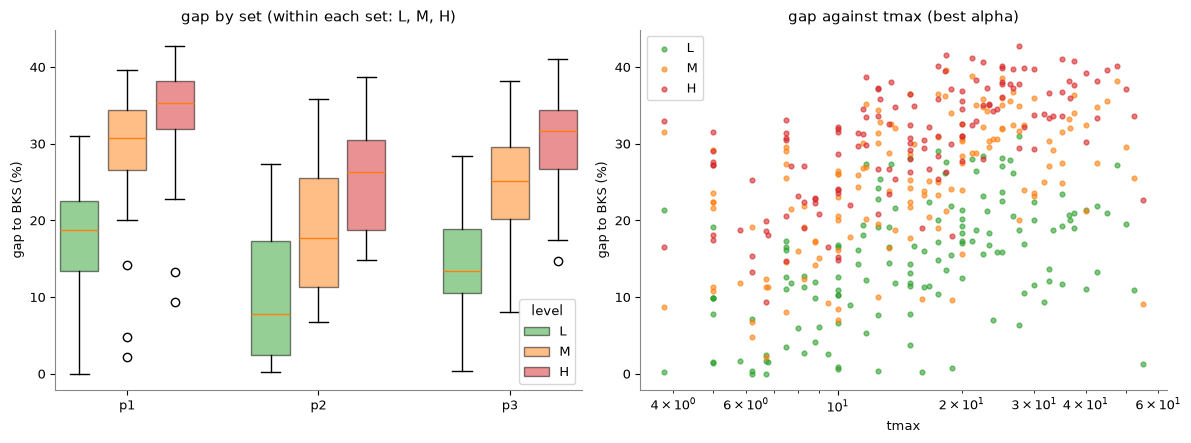

In [27]:
plot_gap_by_set_tmax(best)

The data show the opposite of the expectation: the gap tends to grow with $t_{max}$, and p2, the set with the smallest $t_{max}$, has the lowest gap. We report it as an observation, not an explanation: set and $t_{max}$ are confounded, and the deterministic gap also grows with $t_{max}$ (next section).

## 14. Gap decomposition: deterministic gap and loss due to uncertainty

Where does the gap come from? `det_gap_pct` is the gap of the winner's *deterministic* reward, $100\,(\text{BKS} - \text{det\_reward})/\text{BKS}$. The rest is the loss caused by the random times, $100\,(\text{det\_reward} - \text{exp\_reward})/\text{BKS}$, called `loss_bks_pct`, so that `det_gap_pct + loss_bks_pct = gap_pct` exactly. `uncert_loss_pct` $= 100(1 - \text{exp\_reward}/\text{det\_reward})$ is the same loss relative to the deterministic reward.

In [28]:
best["loss_bks_pct"] = 100 * (best.det_reward - best.exp_reward) / best.bks
dec = best.groupby("level")[["gap_pct", "det_gap_pct", "uncert_loss_pct", "loss_bks_pct"]].agg(["mean", "median"]).loc[levels].round(2)
dec.to_csv(RES / "gap_decomposition_by_level.csv")
print(dec)
det_m = [best[best.level == l].det_gap_pct.mean() for l in levels]
unc_m = [best[best.level == l].loss_bks_pct.mean() for l in levels]
assert np.allclose(np.array(det_m) + unc_m, best.groupby("level").gap_pct.mean().loc[levels])

      gap_pct        det_gap_pct        uncert_loss_pct        loss_bks_pct  \
         mean median        mean median            mean median         mean   
level                                                                         
L       14.65  15.69        3.15    0.0           11.86  11.43        11.50   
M       25.02  26.02        2.96    0.0           22.72  23.36        22.06   
H       30.51  31.56        2.41    0.0           28.79  29.80        28.10   

              
      median  
level         
L      10.96  
M      22.91  
H      29.42  


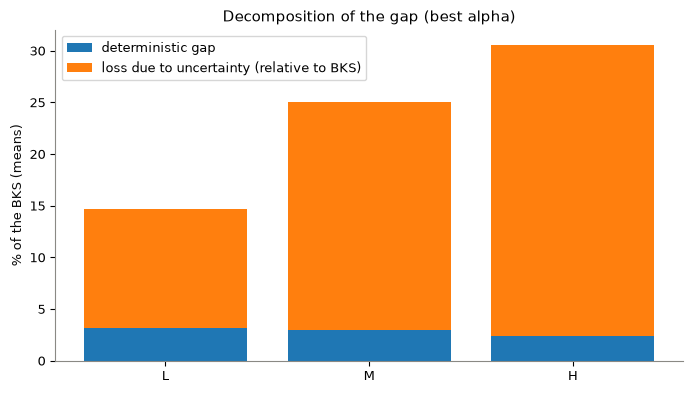

In [29]:
plot_decomposition(det_m, unc_m)

Most of the gap is lost to uncertainty, not to the construction: the deterministic part is a few points at every level (and its median is 0), while the loss due to uncertainty grows with $c$.

Is the loss related to $t_{max}$? The table gives the Spearman correlation of $t_{max}$ with each quantity, by level.

In [30]:
sp_cols = ("gap_pct", "det_gap_pct", "uncert_loss_pct", "loss_bks_pct")
sp_tab = pd.DataFrame({col: {l: round(float(best[best.level == l][["tmax", col]].corr(method="spearman").iloc[0, 1]), 2) for l in levels}
                       for col in sp_cols}).loc[levels]
sp_tab.to_csv(RES / "spearman_tmax_by_level.csv")
sp_tab

,gap_pct,det_gap_pct,uncert_loss_pct,loss_bks_pct
L,0.49,0.56,0.33,0.30
M,0.56,0.54,0.44,0.39
H,0.67,0.59,0.52,0.44


How much slack do the winners' routes have? For every route of the winners in `best.csv`, `st.parse_routes` decodes the route and `st.route_time` gives its expected time; the table summarises expected time / $t_{max}$ by level.

In [31]:
ratios = []
for _, r in best.iterrows():
    inst_r = st.load_instance(r.instance)
    for route in st.parse_routes(r.routes):
        ratios.append((r.level, st.route_time(inst_r, route) / r.tmax))
slack = pd.DataFrame(ratios, columns=["level", "ratio"])
slack_tab = slack.groupby("level").ratio.agg(median="median", q1=lambda x: x.quantile(0.25), p90=lambda x: x.quantile(0.9),
                                            share_within_1pct=lambda x: (x > 0.99).mean()).loc[levels].round(3)
slack_tab.to_csv(RES / "route_slack_by_level.csv")
slack_tab

,median,q1,p90,share_within_1pct
level,,,,
L,0.928,0.860,0.979,0.038
M,0.927,0.851,0.983,0.061
H,0.932,0.853,0.988,0.084


The routes are tight: the median route uses the same share of $t_{max}$ at every level, and the filter that keeps the highest rewards probably keeps the tightest routes (we do not measure this). With so little slack, a sizeable share of the routes overruns, which is the loss measured above.

## 15. Failed routes

What percentage of the routes of the winners overruns $t_{max}$ in the intensive simulation?

In [32]:
fr = best.groupby("level").fail_rate.agg(["mean", "median", "max"]).loc[levels].round(2)
fr.to_csv(RES / "fail_rate_by_level.csv")
fr

,mean,median,max
level,,,
L,12.73,12.73,29.60
M,23.57,25.10,39.35
H,29.45,30.72,42.70


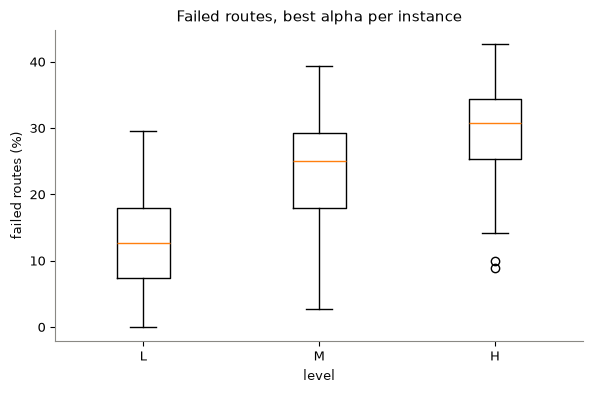

In [33]:
plot_fail_rate(best)

The share of failed routes grows with $c$ and is of the same order as the loss due to uncertainty of the previous section.

## 16. Computing time per run

How long does a run take? Seconds per run, with the runs executed in a process pool (so the times are not for a single isolated process).

In [34]:
levels_t = runs.pivot_table(index="set", columns="level", values="time_s", aggfunc=["mean", "max"])
tm = levels_t[[("mean", l) for l in levels] + [("max", l) for l in levels]].round(3)
tm.to_csv(RES / "time_by_set_level.csv")
print(tm)
print("sum of run times (s):", round(runs.time_s.sum(), 1))

        mean                  max              
level      L      M      H      L      M      H
set                                            
p1     0.159  0.165  0.163  0.230  0.234  0.226
p2     0.072  0.074  0.071  0.119  0.147  0.105
p3     0.164  0.165  0.165  0.234  0.226  0.230
sum of run times (s): 180.6


## 17. Other facts

How often does the greedy candidate win, which $\alpha$ is chosen, where are the worst gaps, and how many distinct candidates survive?

In [35]:
print("winner is the greedy candidate (best-alpha rows):", round(100 * best.winner_is_greedy.mean(), 1), "%")
print("gap > 50 %: runs", int((runs.gap_pct > 50).sum()), "; best-alpha rows", int((best.gap_pct > 50).sum()))
print("alpha chosen as best:", best.alpha.value_counts().sort_index().to_dict())
cols = ["instance", "c", "alpha", "tmax", "bks", "det_reward", "exp_reward", "gap_pct"]
print(best.sort_values("gap_pct", ascending=False)[cols].head(8).round({"exp_reward": 1, "gap_pct": 1}).to_string(index=False))

winner is the greedy candidate (best-alpha rows): 13.2 %
gap > 50 %: runs 0 ; best-alpha rows 0
alpha chosen as best: {0.25: 142, 0.5: 138, 0.75: 143}
instance    c  alpha  tmax  bks  det_reward  exp_reward  gap_pct
  p1.2.k 0.75   0.50  27.5  175       175.0       100.2     42.7
  p1.3.k 0.75   0.50  18.3  135       135.0        78.9     41.6
  p1.4.r 0.75   0.75  21.2  210       195.0       123.5     41.2
  p3.3.s 0.75   0.75  35.0  720       660.0       424.5     41.0
  p3.2.m 0.75   0.75  37.5  620       570.0       367.5     40.7
  p3.2.g 0.75   0.25  22.5  360       340.0       213.7     40.6
  p3.2.q 0.75   0.50  47.5  760       710.0       454.6     40.2
  p1.4.n 0.75   0.25  17.5  155       140.0        92.7     40.2


In [36]:
n_det0 = (best.det_gap_pct.abs() < 1e-9).groupby(best.level).sum().loc[levels]
print("winners with deterministic gap 0 (of", int((best.level == "L").sum()), "per level):", n_det0.to_dict())
div = pd.DataFrame({"share_lt7_distinct_pct": runs.groupby("level").n_distinct.apply(lambda x: 100 * (x < 7).mean()),
                    "share_1_distinct_pct": runs.groupby("level").n_distinct.apply(lambda x: 100 * (x == 1).mean())}).loc[levels]
div.loc["all"] = [100 * (runs.n_distinct < 7).mean(), 100 * (runs.n_distinct == 1).mean()]
div.insert(0, "winners_det_gap0", list(n_det0) + [int(n_det0.sum())])
div.round(1).to_csv(RES / "winners_and_diversity_by_level.csv")
print("runs with < 7 distinct candidates: %.1f %%; with a single one: %.1f %%" % tuple(div.loc["all", ["share_lt7_distinct_pct", "share_1_distinct_pct"]]))
div.round(1)

winners with deterministic gap 0 (of 141 per level): {'L': 72, 'M': 72, 'H': 82}
runs with < 7 distinct candidates: 27.1 %; with a single one: 9.0 %


,winners_det_gap0,share_lt7_distinct_pct,share_1_distinct_pct
level,,,
L,72,27.2,9.0
M,72,27.2,9.0
H,82,27.0,9.0
all,226,27.1,9.0


## Remarks

1. **$\alpha$ hardly matters.** The mean gap of each $(\alpha, c)$ cell varies by less than 0.7 points across $\alpha$; the best $\alpha$ of each (instance, $c$) is 0.25, 0.5 and 0.75 in 142, 138 and 143 of the 423 cases.
2. **The gap grows with the uncertainty level.** With the best $\alpha$ the mean gap is 14.65 / 25.02 / 30.51 % for L / M / H and the medians 15.69 / 26.02 / 31.56, against about 7 / 17 / 24 in Fig. 3 of the paper (read by eye): same order, 7-9 points higher.
3. **Most of the gap is uncertainty, not construction.** The deterministic gap of the winners is 3.15 / 2.96 / 2.41 % (median 0; the winner reaches the BKS in 72 / 72 / 82 of 141 cases) and the loss due to uncertainty, over the BKS, is 11.50 / 22.06 / 28.10 %.
4. **The routes are tight.** The median route uses 0.93 of $t_{max}$ at every level, and the percentage of failed routes is 12.73 / 23.57 / 29.45 %.
5. **Diversity is limited.** In 27.1 % of the runs fewer than 7 distinct candidates survive (9.0 % only one), and the greedy candidate wins in 13.2 % of the best-$\alpha$ rows.
6. **Limits.** Only p1-p3, a fixed number of iterations and a simulation applied after the search. The gap also grows with $t_{max}$ (Spearman 0.49 / 0.56 / 0.67), but set and $t_{max}$ are confounded, so we do not explain it.